# 02 — Linear Algebra in Finance
**MIT 18.642: Topics in Mathematics with Applications in Finance (Fall 2024)**  
Lecture 2: *Linear Algebra*, Dr. Peter J. Kempthorne.

**Learning approach:** begin with a financial portfolio, introduce mathematical definitions alongside applications, and use small, reproducible Python experiments. All prices and scenarios below are **hypothetical**, not current market data.

**Roadmap:** portfolios and vectors → portfolio arithmetic and PnL → long/short and arbitrage → matrices → Markov chains → one-period asset pricing → linear systems → eigenvalues, state dynamics, SVD → Perron–Frobenius.

**Slide references** refer to the slide numbers printed on the MIT lecture (1–35); the supplied PDF contains 55 pages because of slide animations. Some illustrative finance examples and technical qualifications are added here, beyond the lecture.

## 1. What is a portfolio? (Starting point; slides 3–7, 17–19)

**Asset:** Something with economic value that can be held or traded, such as cash, a share of stock, or a bond.

**Portfolio:** A collection of positions in financial assets held by an investor. A *position* specifies how much of each asset is held; positions can be positive (long), zero, or, when permitted, negative (short).

**Example — Alice's portfolio.** Alice holds 10 Apple shares, 5 Microsoft shares, and $\$1,000$ cash. Assume hypothetical prices of $\$200$ and $\$400$ per share, respectively.

| Asset | Quantity held | Price per unit | Position value |
|---|---:|---:|---:|
| Cash | $\$1,000$ | $\$1$ per dollar | $\$1,000$ |
| Apple | 10 shares | $\$200$ | $\$2,000$ |
| Microsoft | 5 shares | $\$400$ | $\$2,000$ |
| **Total** | | | **$\$5,000$** |

The distinction between *quantities* and *portfolio weights* is important: Alice owns 10 Apple shares, but Apple represents $2,000/$5,000 = **40%** of her portfolio's current market value.

### Why linear algebra?
A portfolio may contain hundreds of securities. Vectors store their prices and holdings, and the dot product calculates the total value without writing hundreds of separate terms.

## 2. Vectors of holdings and prices (slides 2–4)

A **vector** in $\mathbb{R}^m$ is an ordered collection of $m$ real numbers. The **holdings vector** $q$ lists quantities owned; the **price vector** $p$ lists the corresponding per-unit prices **in the same order**.

Including cash as asset 0, whose unit price is always $p_0=1$:

$$
q=\begin{pmatrix}1000\\10\\5\end{pmatrix},\qquad
p=\begin{pmatrix}1\\200\\400\end{pmatrix},\qquad
V=q^\top p=\sum_{j=0}^{2}q_jp_j=5000.
$$

**Dot product:** $q^\top p=\sum_j q_jp_j$ is the sum of the individual position values. It is a scalar, not a vector.

**On cash:** $q_0$ is measured in dollars, so $p_0=1$ dollar per dollar; this bookkeeping convention lets us use the same dot-product formula for cash and shares.

The lecture's 500-stock example has $p,q\in\mathbb R^{501}$ once cash is included. The special vectors $\mathbf{0}$ and $\mathbf{1}$ have all entries zero and one, respectively.

**Exercise 1:** Alice buys 2 more Apple shares at $200, paying from cash. What are the new holdings and portfolio value, assuming prices do not change?

In [1]:
# Import NumPy for vector arithmetic.
import numpy as np

# Store hypothetical prices in the order cash, Apple, Microsoft.
prices = np.array([1.0, 200.0, 400.0])

# Store Alice's holdings in the same order.
holdings = np.array([1000.0, 10.0, 5.0])

# Compute the portfolio's market value as a dot product.
value = np.dot(holdings, prices)

# Compute dollar values and fractions invested in each asset.
position_values = holdings * prices
weights = position_values / value

# Display the numerical results.
print('Portfolio value:', f'${value:,.2f}')
print('Position values:', position_values)
print('Portfolio weights:', weights)

# Confirm that the portfolio weights sum to one.
assert np.isclose(weights.sum(), 1.0)

Portfolio value: $5,000.00
Position values: [1000. 2000. 2000.]
Portfolio weights: [0.2 0.4 0.4]


## 3. Vector algebra, portfolio value, and PnL (slides 5–6)

For $v,w\in\mathbb R^m$ and scalar $c$:

- **Scalar multiplication:** $cv=(cv_1,\ldots,cv_m)$.
- **Addition:** $v+w=(v_1+w_1,\ldots,v_m+w_m)$.
- **Dot product:** $v\cdot w=\sum_j v_jw_j$.
- **Euclidean norm:** $\|v\|_2=\sqrt{v\cdot v}$.
- **Orthogonality:** $v\cdot w=0$.

In finance, a **profit and loss (PnL)** is the change in value of a position or portfolio over a period. If holdings $q$ are fixed while prices move from $p_{t-1}$ to $p_t$, then

$$
\mathrm{PnL}_t=V_t-V_{t-1}=q^\top(p_t-p_{t-1}).
$$

**Example:** Tomorrow Apple rises from $\$200$ to $\$210$ and Microsoft falls from $\$400$ to $\$390$. With Alice's holdings unchanged, the gains are $10(10)=+100$ and $5(-10)=-50$, so the total PnL is **+$50**. Cash is unchanged.

**Important assumption:** This formula assumes no deposits, withdrawals, trades during the price interval, dividends, fees, or financing costs. Total investment return may also include distributions such as dividends.

**Exercise 2:** What happens to Alice's PnL if Apple instead falls by $\$10$ and Microsoft rises by $\$20$?

In [2]:
# Define tomorrow's hypothetical closing prices.
prices_next = np.array([1.0, 210.0, 390.0])

# Calculate each asset's change in price.
price_changes = prices_next - prices

# Calculate PnL from the fixed holdings.
pnl = np.dot(holdings, price_changes)

# Confirm the same result by subtracting total values.
assert np.isclose(pnl, np.dot(holdings, prices_next) - value)

# Display the changes and the net result.
print('Price changes:', price_changes)
print('PnL:', f'${pnl:,.2f}')

Price changes: [  0.  10. -10.]
PnL: $50.00


## 4. Rebalancing: changing holdings without adding money (slide 4)

**Rebalancing** means adjusting the quantities held in different assets. Let $\Delta q$ be the vector of trades executed at price $p_t$. Then

$$q_{t+1}=q_t+\Delta q.$$

A **self-financing rebalance** uses only the existing portfolio's funds. With cash included and no transaction costs,

$$p_t^\top\Delta q=0.$$

**Example:** Alice purchases 2 additional Apple shares at $\$200$ each and finances the purchase by reducing cash by $400:

$$\Delta q=(-400,2,0)^\top,\quad p^\top\Delta q=-400+2(200)=0.$$

The portfolio still has a value of $5,000 immediately after the trade. Only its composition changes.

**Non-example:** If Alice deposits an additional $\$400$ to purchase those shares, the investment account's total value increases by $400; this is not a self-financing rebalance.

**Timing convention:** The lecture distinguishes end-of-day prices from holdings set for the next day. Keep price and holding timestamps aligned when computing PnL.


## Vector Algebra with Portfolios

### 1. Two Portfolios

Suppose we have $m$ stocks and one cash position. We represent the holdings of two portfolios at the beginning of day $t$ by the vectors

$$
\mathbf{q}_t=
\begin{pmatrix}
q_0(t)\\
q_1(t)\\
\vdots\\
q_m(t)
\end{pmatrix},
\qquad
\mathbf{w}_t=
\begin{pmatrix}
w_0(t)\\
w_1(t)\\
\vdots\\
w_m(t)
\end{pmatrix}.
$$

Here:

- $q_0(t)$ and $w_0(t)$ are the cash positions.
- $q_j(t)$ and $w_j(t)$ are the numbers of shares of stock $j$ held in the respective portfolios.
- $\mathbf{p}_t$ denotes the vector of asset prices at the end of day $t$.
- The cash asset has price $p_0(t)=1$.

We assume that the holdings remain unchanged during day $t$.

### 2. Beginning-of-Day (BOD) Portfolio Value

**Definition:** The beginning-of-day value of a portfolio is the total market value of its holdings at the beginning of the trading day.

Following the convention in the slides, the beginning-of-day value is calculated using the previous day's closing prices.

For the two portfolios:

$$
\boxed{
V^{\mathrm{BOD}}(\mathbf{q}_t,t)
=
\langle\mathbf{q}_t,\mathbf{p}_{t-1}\rangle
=
\mathbf{q}_t^\top\mathbf{p}_{t-1}
}
$$

and

$$
\boxed{
V^{\mathrm{BOD}}(\mathbf{w}_t,t)
=
\langle\mathbf{w}_t,\mathbf{p}_{t-1}\rangle
=
\mathbf{w}_t^\top\mathbf{p}_{t-1}.
}
$$

### 3. End-of-Day (EOD) Portfolio Value

**Definition:** The end-of-day value of a portfolio is the total market value of its holdings at the end of the trading day, calculated using the closing prices on day $t$.

For the two portfolios:

$$
\boxed{
V^{\mathrm{EOD}}(\mathbf{q}_t,t)
=
\langle\mathbf{q}_t,\mathbf{p}_t\rangle
=
\mathbf{q}_t^\top\mathbf{p}_t
}
$$

and

$$
\boxed{
V^{\mathrm{EOD}}(\mathbf{w}_t,t)
=
\langle\mathbf{w}_t,\mathbf{p}_t\rangle
=
\mathbf{w}_t^\top\mathbf{p}_t.
}
$$

### 4. Portfolio Net Gain: Profit and Loss (PnL)

**Definition:** Profit and Loss (PnL) measures the change in a portfolio's value over a specified period.

For a portfolio whose holdings remain unchanged during day $t$:

$$
\begin{aligned}
\mathrm{PnL}(\mathbf{q}_t,t)
&=
V^{\mathrm{EOD}}(\mathbf{q}_t,t)
-
V^{\mathrm{BOD}}(\mathbf{q}_t,t)\\
&=
\mathbf{q}_t^\top\mathbf{p}_t
-
\mathbf{q}_t^\top\mathbf{p}_{t-1}\\
&=
\boxed{
\mathbf{q}_t^\top
(\mathbf{p}_t-\mathbf{p}_{t-1})
}.
\end{aligned}
$$

Similarly, for the second portfolio:

$$
\boxed{
\mathrm{PnL}(\mathbf{w}_t,t)
=
\mathbf{w}_t^\top
(\mathbf{p}_t-\mathbf{p}_{t-1})
}.
$$

**Interpretation:** The daily profit or loss is the dot product of the holdings vector with the vector of daily price changes.

These formulas measure gains from price changes alone. Dividends, transaction costs, and other cash flows are excluded.

---

### 5. Example: Comparing Two Portfolios

Suppose Alice and Bob each own portfolios consisting of Apple and Microsoft shares, together with cash.

Their beginning-of-day holdings are:

| Asset | Alice | Bob |
|---|---:|---:|
| Cash | $\$1,000$ | $\$500$ |
| Apple | 10 shares | 5 shares |
| Microsoft | 5 shares | 10 shares |

The price vectors are:

$$
\mathbf{p}_{t-1}
=
\begin{pmatrix}
1\\
200\\
400
\end{pmatrix},
\qquad
\mathbf{p}_t
=
\begin{pmatrix}
1\\
210\\
390
\end{pmatrix}.
$$

The holdings vectors are:

$$
\mathbf{q}_t=
\begin{pmatrix}
1000\\
10\\
5
\end{pmatrix},
\qquad
\mathbf{w}_t=
\begin{pmatrix}
500\\
5\\
10
\end{pmatrix}.
$$

#### Alice's Portfolio

Beginning-of-day value:

$$
V^{\mathrm{BOD}}(\mathbf{q}_t,t)
=
1000+10(200)+5(400)
=
\$5000.
$$

End-of-day value:

$$
V^{\mathrm{EOD}}(\mathbf{q}_t,t)
=
1000+10(210)+5(390)
=
\$5050.
$$

Therefore,

$$
\boxed{\mathrm{PnL}(\mathbf{q}_t,t)=\$50.}
$$

#### Bob's Portfolio

Beginning-of-day value:

$$
V^{\mathrm{BOD}}(\mathbf{w}_t,t)
=
500+5(200)+10(400)
=
\$5500.
$$

End-of-day value:

$$
V^{\mathrm{EOD}}(\mathbf{w}_t,t)
=
500+5(210)+10(390)
=
\$5450.
$$

Therefore,

$$
\boxed{\mathrm{PnL}(\mathbf{w}_t,t)=-\$50.}
$$

### 6. Interpretation

Although Alice and Bob hold the same two stocks, their portfolio performances differ because they hold different quantities of each stock.

Apple's price increased by $\$10$, while Microsoft's price decreased by $10.

Alice holds more Apple shares than Microsoft shares, so her portfolio gains $50.

Bob holds more Microsoft shares than Apple shares, so his portfolio loses $50.

This illustrates how **portfolio performance depends on both asset price changes and the portfolio's holdings vector**.

---

### 7. Exercises

**Exercise 1.** Suppose Alice increases her Apple holdings from 10 shares to 20 shares before the trading day begins, while keeping all other holdings unchanged. Calculate her new daily PnL.

**Exercise 2.** Suppose Apple and Microsoft both increase in price by $10. Calculate the daily PnL of Alice's and Bob's original portfolios.

**Exercise 3.** Explain why the cash position does not contribute to the PnL in this example.

**Exercise 4.** Suppose two portfolios have identical holdings vectors at the beginning of the trading day. Can they have different daily PnL values under the assumptions of this model? Explain.


In [3]:
# Record the trade as cash outflow and Apple share purchase.
trade = np.array([-400.0, 2.0, 0.0])

# Check that the rebalance is self-financing at today's prices.
assert np.isclose(np.dot(trade, prices), 0.0)

# Apply the trade to obtain the new holdings.
rebalanced = holdings + trade

# Compare values before and immediately after the trade.
print('New holdings:', rebalanced)
print('Value after rebalance:', np.dot(rebalanced, prices))

# Compute next-day PnL with the rebalanced holdings.
print('Next-day PnL with new holdings:', np.dot(rebalanced, price_changes))

New holdings: [600.  12.   5.]
Value after rebalance: 5000.0
Next-day PnL with new holdings: 70.0


## 5. Long and short positions; zero-cost portfolios (slide 7)

**Long position:** Positive ownership of an asset. Its value generally increases when the asset's price increases.

**Short position:** A negative exposure to an asset. In a typical stock short sale, the investor borrows shares, sells them, and must later return equivalent shares; gains and losses reverse relative to a long position. Borrowing fees, margin, and dividends matter in practice.

**Long/short portfolio:** A portfolio with both positive and negative positions. For two holdings vectors $q,w$, their difference $d=q-w$ represents a long position in $q$ and short exposure to $w$.

**Zero-cost portfolio:** A position $d$ satisfying $p_0^\top d=0$ at initiation (under the model's pricing convention). Zero *net* initial cost does **not** imply zero risk or no collateral requirement.

**Example:** At hypothetical prices $p_0=(100,50)$, long one share of stock A and short two shares of stock B:

$$d=(1,-2)^\top,\qquad p_0^\top d=100-2(50)=0.$$

If prices move to $(110,60)$, its payoff/PnL is $110-2(60)=-10$. It is zero-cost, but it loses money.

### Arbitrage (idealized one-period definition)
An **arbitrage** is a portfolio whose initial cost is nonpositive, whose terminal payoff is nonnegative in every possible state, and which offers a strictly positive net benefit in at least one state, with the usual financing conventions. A zero-cost version has

$$V_0=0,\quad V_T(\omega)\geq0\text{ for every }\omega,\quad V_T(\omega)>0\text{ for some }\omega.$$

A profitable outcome in **one observed scenario** is not enough to prove arbitrage. At initiation, future prices are uncertain.

**Exercise 3:** Is the long-A/short-two-B portfolio an arbitrage merely because its initial cost is zero?


### Digression: Short Selling and the Role of a Broker

#### 1. What Is a Short Position?

**Definition:** A short position is a financial position that generally benefits when the price of an asset decreases.

For stocks, a short position is commonly established through **short selling**: an investor borrows shares, sells them in the market, and later purchases shares to return to the lender.

A **long position**, in contrast, involves owning an asset and generally benefits when its price increases.

In the portfolio vector notation of Lecture 2:

$$
\mathbf{q}=
\begin{pmatrix}
q_0\\
q_1\\
\vdots\\
q_m
\end{pmatrix},
$$

we interpret:

- $q_j>0$: A long position in asset $j$.
- $q_j<0$: A short position in asset $j$.
- $q_j=0$: No position in asset $j$.

The negative sign represents an obligation associated with the borrowed shares, rather than ownership of a negative number of physical shares.

#### 2. What Is a Broker?

**Definition:** A broker is a financial intermediary that facilitates transactions in financial markets on behalf of investors.

For short selling, the broker typically helps the investor:

1. Locate shares available to borrow.
2. Arrange the borrowing of those shares.
3. Sell the borrowed shares in the market.
4. Hold the required collateral and monitor margin requirements.
5. Arrange the return of equivalent shares when the short position is closed.

The shares may be borrowed from another client, a financial institution, or another available lending source.

The broker does not necessarily own the shares being lent.

#### 3. Example: Alice Shorts Apple Stock

Suppose Alice believes that Apple's stock price will decrease.

For simplicity, assume that Apple's current stock price is $200 per share.

Alice wants to short 10 shares.

**Step 1: Borrowing the shares**

Alice contacts her broker, who arranges for her to borrow 10 Apple shares.

Alice now has an obligation to return 10 Apple shares in the future.

**Step 2: Selling the borrowed shares**

Alice sells the 10 borrowed shares at $200 each.

The sale generates:

$$
10\times \$200=\$2000.
$$

The $2,000 in proceeds is held in her brokerage account, subject to the broker's collateral and margin rules. It is not necessarily available for Alice to withdraw.

**Step 3: The stock price decreases**

Suppose Apple's stock price decreases to $150.

Alice purchases 10 shares in the market for:

$$
10\times \$150=\$1500.
$$

**Step 4: Returning the shares**

Alice returns the 10 shares to the lender through her broker.

Her gross profit is:

$$
\begin{aligned}
\text{Profit}
&=\text{Sale Proceeds}-\text{Repurchase Cost}\\
&=2000-1500\\
&=\boxed{\$500}.
\end{aligned}
$$

Thus, Alice earns $500 because the stock price decreased.

This calculation excludes borrowing fees, commissions, financing costs, and any dividends Alice may be required to compensate the share lender for.

#### 4. What If the Stock Price Increases?

Suppose instead that Apple's stock price increases from $\$200$ to $250.

Alice must still return 10 shares.

To close the position, she purchases 10 shares at $250 each:

$$
10\times \$250=\$2500.
$$

Her gross profit or loss is:

$$
\begin{aligned}
\text{PnL}
&=2000-2500\\
&=\boxed{-\$500}.
\end{aligned}
$$

Therefore, Alice loses $500.

**Important:** Unlike a conventional long stock position, whose loss from a positive purchase price is limited to the amount invested, a short stock position has theoretically unlimited potential losses because the stock price has no fixed upper bound.

#### 5. Connection to Vector Algebra

Recall from Lecture 2 that the profit and loss of a portfolio with fixed holdings is

$$
\boxed{
\mathrm{PnL}(\mathbf{q}_t,t)
=
\mathbf{q}_t^\top
(\mathbf{p}_t-\mathbf{p}_{t-1}).
}
$$

Suppose Alice holds a short position of 10 Apple shares:

$$
q_{\mathrm{Apple}}=-10.
$$

Initially, Apple's price is $\$200$, and subsequently it decreases to $150.

Then:

$$
\begin{aligned}
\mathrm{PnL}
&=q_{\mathrm{Apple}}(p_t-p_{t-1})\\
&=(-10)(150-200)\\
&=(-10)(-50)\\
&=\boxed{\$500}.
\end{aligned}
$$

This is precisely the gross profit calculated from the short-selling transaction.

Similarly, if Apple's price increases to $250:

$$
\mathrm{PnL}
=
(-10)(250-200)
=
\boxed{-\$500}.
$$

Thus, **negative holdings naturally represent short positions in the linear algebra formulation of portfolio PnL**.

#### 6. A Zero-Cost Long/Short Portfolio

Suppose Alice takes the following positions:

- Long 10 shares of Microsoft at $\$200$ per share.
- Short 10 shares of Apple at $\$200$ per share.

Ignoring collateral requirements and transaction costs, the proceeds from shorting Apple exactly offset the cost of purchasing Microsoft.

The holdings vector is

$$
\mathbf{q}=
\begin{pmatrix}
10\\
-10
\end{pmatrix},
$$

and the price vector is

$$
\mathbf{p}_0=
\begin{pmatrix}
200\\
200
\end{pmatrix}.
$$

The initial net portfolio value is

$$
V_0=\mathbf{q}^\top\mathbf{p}_0
=10(200)-10(200)
=\boxed{0}.
$$

This is an example of a **zero-cost long/short portfolio** in the mathematical model.

However, zero net cost does not mean that no collateral or margin is required in practice.

Suppose Microsoft's price rises to $\$220$ and Apple's price falls to $180.

Then:

$$
\mathbf{p}_1=
\begin{pmatrix}
220\\
180
\end{pmatrix}.
$$

The portfolio's gross PnL is

$$
\begin{aligned}
\mathrm{PnL}
&=\mathbf{q}^\top(\mathbf{p}_1-\mathbf{p}_0)\\
&=10(20)+(-10)(-20)\\
&=\boxed{\$400}.
\end{aligned}
$$

Notice that this portfolio profits from both Microsoft's price increase and Apple's price decrease.

**Is this an arbitrage?**

Not necessarily.

The portfolio has zero initial net value in the simplified model, but it can lose money if the prices move in the opposite directions.

An arbitrage opportunity requires a nonnegative payoff in every possible scenario, with a strictly positive payoff in at least one scenario, together with a nonpositive initial cost.

A zero-cost long/short portfolio is therefore not automatically an arbitrage.

---

### 7. Exercises

**Exercise 1.** Alice shorts 20 shares of a stock at $\$100$ per share. The price subsequently decreases to $80. Calculate her gross profit.

**Exercise 2.** Suppose Alice shorts 10 shares at $\$200$, but the stock price increases to $300. Calculate her gross loss.

**Exercise 3.** Why does Alice need a broker to arrange a conventional short sale rather than simply selling shares she does not own?

**Exercise 4.** Explain why a zero-cost long/short portfolio is not necessarily an arbitrage opportunity.


In [4]:
# Set initial prices for stocks A and B.
p0 = np.array([100.0, 50.0])

# Define a long/short portfolio: one A, short two B.
long_short = np.array([1.0, -2.0])

# Define two possible future price scenarios.
future_prices = np.array([[110.0, 60.0], [120.0, 45.0]])

# Compute initial cost and payoffs in both scenarios.
initial_cost = p0 @ long_short
scenario_payoffs = future_prices @ long_short

# Print the result, including the losing scenario.
print('Initial cost:', initial_cost)
print('Payoffs by scenario:', scenario_payoffs)

Initial cost: 0.0
Payoffs by scenario: [-10.  30.]


## 6. Linear independence, span, and basis (slides 8–9)

A collection $v_1,\ldots,v_k$ is **linearly independent** if $\sum_i c_iv_i=0$ implies all $c_i=0$. Their **span** consists of all linear combinations $\sum_i c_iv_i$. A **basis** is an independent spanning collection.

**Financial interpretation:** Each asset has a payoff vector across possible future market scenarios. If one asset's payoff vector is a linear combination of others, it can be **replicated** by a portfolio of those assets. This is the key connection between linear independence and derivative pricing.

**Example:** Two possible future states. Asset A pays $(1,0)$ and asset B pays $(0,1)$; together their payoffs span $\mathbb R^2$. A claim paying $(3,5)$ is replicated by 3 units of A and 5 units of B.

**Non-example:** Payoffs $(1,2)$ and $(2,4)$ are dependent, so these two assets alone cannot replicate every possible two-state payoff.

**Exercise 4:** Can $(2,1)$ be replicated using the assets with payoff vectors $(1,0)$ and $(0,1)$? Specify holdings.

## 7. Matrices and matrix operations (slides 10–15)

A matrix $A\in\mathbb R^{m\times n}$ is an array with $m$ rows and $n$ columns. Its $j$-th column is a vector in $\mathbb R^m$.

- **Transpose:** $(A^\top)_{ij}=A_{ji}$.
- **Matrix–vector multiplication:** $(Aq)_i=\sum_j A_{ij}q_j$.
- **Matrix–matrix multiplication:** $(AB)_{ij}=\sum_k A_{ik}B_{kj}$ when dimensions agree.
- **Symmetric matrix:** $A=A^\top$.
- **Identity matrix:** $I_nq=q$.
- **Diagonal matrix:** entries off the main diagonal are zero.
- **Zero and all-ones matrices:** $0$ and $J$.

Matrix multiplication is associative and distributive, but generally **not commutative**: $AB\ne BA$. Also $(AB)^\top=B^\top A^\top$.

**Financial example:** Rows of a matrix can encode future economic scenarios; columns encode assets. Multiplying by a holdings vector gives the value of a portfolio in each scenario.

**Exercise 5:** If $A$ is a $3\times2$ scenario-price matrix and $q$ is a two-asset holdings vector, what are the dimensions of $Aq$?

In [5]:
# Define a scenario-price matrix: three states and two assets.
scenario_matrix = np.array([[110.0, 60.0], [120.0, 45.0], [90.0, 55.0]])

# Define a portfolio holding two units of A and one unit of B.
q_two_assets = np.array([2.0, 1.0])

# Compute the portfolio's value in each scenario.
scenario_values = scenario_matrix @ q_two_assets

# Print matrix dimensions and resulting values.
print('Matrix shape:', scenario_matrix.shape)
print('Scenario values:', scenario_values)

# Check the identity-matrix property.
assert np.allclose(np.eye(2) @ q_two_assets, q_two_assets)

Matrix shape: (3, 2)
Scenario values: [280. 285. 235.]


### Preliminary Definitions: Stochastic Processes and Markov Chains

Before introducing stochastic matrices, we briefly define two concepts: **stochastic processes** and **Markov chains**.

#### 1. Stochastic Process

**Definition:** A stochastic process is a collection of random variables indexed by time:

$$
\{X_t\}_{t\in T},
$$

where $X_t$ represents the state of a system at time $t$.

Unlike a deterministic process, whose evolution is completely determined by its initial conditions and governing rules, a stochastic process involves randomness.

**Example (Financial Markets):**

Let $X_t$ denote the price of Apple stock on day $t$.

The sequence

$$
X_0,X_1,X_2,\ldots
$$

is a stochastic process because future stock prices are uncertain.

Stochastic processes can have discrete or continuous time indices and discrete or continuous state spaces.

#### 2. Markov Chain

**Definition:** A Markov chain is a stochastic process with a discrete state space that satisfies the **Markov property**: given the present state, the probability distribution of the next state does not depend on the earlier states.

Mathematically, for a discrete-time Markov chain,

$$
\boxed{
P(X_{t+1}=j\mid X_t=i,X_{t-1},\ldots,X_0)
=
P(X_{t+1}=j\mid X_t=i).
}
$$

In simple terms, **the present state contains all the information from the past needed to predict the probability distribution of the next state**.

#### 3. Example: A Simple Financial Market Model

Suppose we model the market using only two possible states:

- **Bull market (B):** A period characterized by generally rising stock prices.
- **Bear market (R):** A period characterized by generally falling stock prices.

Assume the following hypothetical transition probabilities:

| Current state | Next: Bull | Next: Bear |
|---|---:|---:|
| Bull | 0.8 | 0.2 |
| Bear | 0.3 | 0.7 |

For example, if the market is currently in a bull state, our model assigns an 80% probability that it will remain in a bull state in the next period.

These probabilities are assumptions for illustration, not empirical estimates.

#### 4. Connection to Stochastic Matrices

**Definition:** A stochastic matrix is a square matrix with nonnegative entries whose rows or columns sum to 1, depending on the convention used.

In MIT 18.642, we use the **column-stochastic convention**, where each column sums to 1.

For our example, the transition matrix is

$$
\boxed{
A=
\begin{pmatrix}
0.8 & 0.3\\
0.2 & 0.7
\end{pmatrix}.
}
$$

Here,

$$
A_{ij}=P(X_{t+1}=i\mid X_t=j).
$$

Notice that:

$$
0.8+0.2=1,
\qquad
0.3+0.7=1.
$$

Thus, $A$ is a column-stochastic matrix.

Suppose the market is currently in the bull state with certainty. Its probability distribution is

$$
\boldsymbol{\pi}(0)=
\begin{pmatrix}
1\\
0
\end{pmatrix}.
$$

The probability distribution after one period is

$$
\begin{aligned}
\boldsymbol{\pi}(1)
&=A\boldsymbol{\pi}(0)\\
&=
\begin{pmatrix}
0.8 & 0.3\\
0.2 & 0.7
\end{pmatrix}
\begin{pmatrix}
1\\
0
\end{pmatrix}\\
&=
\begin{pmatrix}
0.8\\
0.2
\end{pmatrix}.
\end{aligned}
$$

Therefore, after one period:

- Probability of a bull market: 80%.
- Probability of a bear market: 20%.

More generally, for a time-homogeneous Markov chain,

$$
\boxed{
\boldsymbol{\pi}(t+1)=A\boldsymbol{\pi}(t).
}
$$

Repeating this operation gives

$$
\boxed{
\boldsymbol{\pi}(t)=A^t\boldsymbol{\pi}(0).
}
$$

This is the central connection between **Markov chains and linear algebra**: the evolution of a probability distribution can be described by repeated multiplication by a stochastic matrix.

We will study Markov chains and stochastic processes more thoroughly later in the course.


## 8. Markov chains and stochastic matrices (slide 16)

**Markov chain:** A stochastic process whose next-state distribution depends on the present state, not on the full past, once the present state is known.

Let $S_t$ denote a state at time $t$, and define the **column-stochastic** transition matrix

$$A_{ij}=P(S_{t+1}=i\mid S_t=j),\quad A_{ij}\geq0,\quad\sum_i A_{ij}=1.$$

For the probability vector $\pi_t$ (its entries sum to 1),

$$\pi_{t+1}=A\pi_t,\qquad \pi_t=A^t\pi_0.$$

A **stationary distribution** $\pi_*$, defined as $\lim_{t \to \infty}\pi_t$, satisfies $A\pi_*=\pi_*$. It need not be the limiting distribution for every Markov chain; convergence requires additional conditions.

**Hypothetical credit-rating example:** A borrower may be in either a *Strong* or *Weak* credit state. Each month, a Strong borrower remains Strong with probability 0.9; a Weak borrower becomes Strong with probability 0.3. With columns indexed by the current state:

$$A=\begin{pmatrix}0.9&0.3\\0.1&0.7\end{pmatrix}.$$

This is a simplified pedagogical model, not a calibrated credit-rating transition matrix.

**Exercise 6:** Starting with $\pi_0=(1,0)^\top$, what is $\pi_1$?

In [6]:
# Define a column-stochastic transition matrix.
transition = np.array([[0.9, 0.3], [0.1, 0.7]])

# Verify that every column sums to one.
assert np.allclose(transition.sum(axis=0), 1.0)

# Begin with certainty that the borrower is in the Strong state.
probabilities = np.array([1.0, 0.0])

# Track the probability distribution over twelve months.
history = [probabilities.copy()]
for month in range(12):
    # Update the distribution by one Markov transition.
    probabilities = transition @ probabilities
    # Save a copy of the current distribution.
    history.append(probabilities.copy())

# Display the distribution after twelve months.
print('Month 12:', history[-1])

# Solve for the stationary distribution using the eigenvector for eigenvalue one.
eigenvalues, eigenvectors = np.linalg.eig(transition)
stationary = np.real(eigenvectors[:, np.argmin(np.abs(eigenvalues - 1))])
stationary = stationary / stationary.sum()

# Check and display stationarity.
assert np.allclose(transition @ stationary, stationary)
print('Stationary distribution:', stationary)

Month 12: [0.7505442 0.2494558]
Stationary distribution: [0.75 0.25]


## 9. Slide 17 — Single-Period Market Model
### 1. Positive matrices (prices/costs)

A matrix $A=(a_{ij})$ is called **positive** if

$$
a_{ij}>0,\qquad 1\leq i\leq m,\quad 1\leq j\leq n.
$$

In financial applications, such a matrix can represent asset prices under different possible market scenarios.

### 2. Single-period market model

Consider a financial market consisting of:

- $n$ assets, indexed by $j=1,\ldots,n$.
- Two times: $t=0$ (initial time) and $t=T$ (terminal time).
- $m$ possible market scenarios at time $T$:

$$
\Omega=\{\omega_1,\omega_2,\ldots,\omega_m\}.
$$

For each asset $j$, let $A_t^j$ denote its price at time $t$.

The asset-price processes are represented by

$$
\mathcal A=\{A_t^1,A_t^2,\ldots,A_t^n;\ t=0,T\}.
$$

Here:

- $A_0^j$ is the **known initial price** of asset $j$.
- $A_T^j$ is its **random terminal price**, which depends on the scenario realized at time $T$.

The scenario-dependent terminal-price matrix is

$$
A=(a_{ij})\in\mathbb R^{m\times n},
$$

where

$$
a_{ij}=A_T^j(\omega_i).
$$

Thus, each **row** corresponds to a market scenario and each **column** corresponds to an asset.

### Example — Two stocks and three market scenarios

Suppose we invest in Apple and Microsoft shares.

Their current prices are

$$
\mathbf A_0=
\begin{pmatrix}
200\\
400
\end{pmatrix}.
$$

Consider three possible scenarios one year later:

| Scenario | Apple | Microsoft |
|---|---:|---:|
| Bull market $\omega_1$ | $\$240$ | $\$460$ |
| Stable market $\omega_2$ | $\$205$ | $\$410$ |
| Bear market $\omega_3$ | $\$160$ | $\$340$ |

These are hypothetical prices.

The terminal-price matrix is

$$
A=
\begin{pmatrix}
240 & 460\\
205 & 410\\
160 & 340
\end{pmatrix}.
$$

This is a $3\times 2$ positive matrix.

**Observation:** We do not know which scenario will occur. The matrix describes the possible future prices, not their probabilities.

---

## Slide 18 — Portfolios and Arbitrage

### 1. Portfolio of assets

A portfolio is represented by a vector

$$
\mathbf q=
\begin{pmatrix}
q_1\\
q_2\\
\vdots\\
q_n
\end{pmatrix},
$$

where $q_j$ is the number of units of asset $j$ held by the investor.

A positive position means we hold the asset (**long position**). A negative position represents a **short position**, when short selling is permitted.

### 2. Initial portfolio cost

The initial cost of the portfolio is

$$
V_0=\sum_{j=1}^n A_0^j q_j
=\mathbf A_0^\top\mathbf q.
$$

This is the dot product of the initial-price vector and the portfolio-holdings vector.

### 3. Terminal portfolio payoff

In scenario $\omega_i$, the terminal value is

$$
V_T(\omega_i)=\sum_{j=1}^n A_T^j(\omega_i)q_j.
$$

Collecting the payoffs for all scenarios gives

$$
\mathbf V_T=
\begin{pmatrix}
V_T(\omega_1)\\
V_T(\omega_2)\\
\vdots\\
V_T(\omega_m)
\end{pmatrix}
=A\mathbf q.
$$

**Interpretation:** Matrix multiplication converts a portfolio of asset holdings into a vector of possible future portfolio values.

### Example — Portfolio payoff

Suppose Alice holds 10 Apple shares and 5 Microsoft shares:

$$
\mathbf q=
\begin{pmatrix}
10\\
5
\end{pmatrix}.
$$

Her initial portfolio cost is

$$
V_0=200(10)+400(5)=4000.
$$

Using the terminal-price matrix from Slide 17,

$$
\mathbf V_T=
\begin{pmatrix}
240 & 460\\
205 & 410\\
160 & 340
\end{pmatrix}
\begin{pmatrix}
10\\
5
\end{pmatrix}
=
\begin{pmatrix}
4700\\
4100\\
3300
\end{pmatrix}.
$$

Therefore:

| Scenario | Portfolio value | Profit/loss |
|---|---:|---:|
| Bull | $\$4,700$ | $+\$700$ |
| Stable | $\$4,100$ | $+\$100$ |
| Bear | $\$3,300$ | $-\$700$ |

The profit/loss is calculated as $V_T(\omega_i)-V_0$, assuming no intermediate cash flows.

### 4. Arbitrage portfolio

An **arbitrage portfolio** is a portfolio $\mathbf q$ satisfying

$$
V_0=\mathbf A_0^\top\mathbf q\leq 0
$$

and

$$
V_T(\omega_i)\geq 0
\qquad\text{for every scenario }\omega_i,
$$

with

$$
V_T(\omega_i)>0
\qquad\text{for at least one scenario}.
$$

Thus, the portfolio requires no positive initial investment and cannot produce a negative terminal payoff, while producing a positive payoff in at least one possible scenario.

### Example — Arbitrage through identical assets

Suppose two securities have identical future payoffs of $100 in every scenario, but their current prices are different:

- Asset A costs $\$95$.
- Asset B costs $\$100$.

Buy one unit of A and short one unit of B.

The initial cost is

$$
V_0=95-100=-5.
$$

The terminal payoff is

$$
V_T(\omega)=100-100=0
$$

in every scenario.

We receive $5 immediately without any future liability. This is an arbitrage opportunity.

**Technical note:** This example is an immediate cash-inflow arbitrage. The slide's stated condition additionally requires a strictly positive terminal payoff in some scenario. If we include the initial $\$5$ as cash carried to time $T$, the complete strategy satisfies that condition, assuming cash can be held without loss.

---

## Slide 19 — No Arbitrage, Market Completeness, and Pricing Measures

### 1. Cost–payoff space

For each portfolio $\mathbf q\in\mathbb R^n$, we associate its initial cost and terminal payoff vector:

$$
(V_0,\mathbf V_T)\in\mathbb R^{m+1}.
$$

The set of all attainable cost–payoff combinations is

$$
\mathcal P=
\left\{
(V_0,\mathbf V_T)\in\mathbb R^{m+1}:
\mathbf q\in\mathbb R^n
\right\},
$$

where $V_0=\mathbf A_0^\top\mathbf q$ and $\mathbf V_T=A\mathbf q$.

This set describes what the available assets allow investors to construct.

### 2. Market completeness

A market is called **complete** if every terminal payoff vector

$$
\mathbf v\in\mathbb R^m
$$

can be realized by some portfolio $\mathbf q$.

Equivalently, for every $\mathbf v$, the linear system

$$
A\mathbf q=\mathbf v
$$

has a solution.

This means the payoff matrix has full row rank:

$$
\operatorname{rank}(A)=m.
$$

**Explanation:** A complete market allows investors to replicate any desired payoff across the possible scenarios.

For example, suppose there are two scenarios: a bull market and a bear market. A complete market allows us to construct a portfolio that pays $\$100$ in the bull market and $\$0$ in the bear market, as well as any other pair of payoffs.

### 3. Pricing measure

A **pricing measure** $Q^*$ assigns probabilities to the possible terminal scenarios:

$$
Q^*(\omega_i)=q_i^*>0,
$$

with

$$
\sum_{i=1}^m q_i^*=1.
$$

These probabilities are used to price assets through their expected future payoffs.

The slide introduces the pricing relation

$$
A_0^j
=
\alpha\,\mathbb E_{Q^*}[A_T^j]
=
\alpha\sum_{i=1}^m A_T^j(\omega_i)q_i^*,
$$

for every asset $j=1,\ldots,n$, where $\alpha>0$ is a **discount factor**.

A discount factor converts a future monetary amount into its present value.

For example, with a one-period risk-free interest rate $r$,

$$
\alpha=\frac{1}{1+r}.
$$

**Important:** The pricing probabilities $q_i^*$ need not equal the real-world probabilities of the scenarios. They are chosen to make discounted expected payoffs consistent with current asset prices.

### 4. No arbitrage and uniqueness

The important relationships are:

- **No arbitrage:** In the standard finite-state, frictionless model, absence of arbitrage is equivalent to the existence of a strictly positive state-price vector. With a traded positive-payoff risk-free asset, this can be expressed using a strictly positive pricing measure $Q^*$.
- **Market completeness:** Every possible terminal payoff can be replicated by a portfolio.
- **Completeness and uniqueness:** In an arbitrage-free market with a traded risk-free asset, the pricing measure is unique if and only if the market is complete.

These results form the basis of the **Fundamental Theorems of Asset Pricing**.

### Example — Pricing a contingent payoff

Suppose there are two equally likely scenarios under the pricing measure:

$$
Q^*(\omega_1)=Q^*(\omega_2)=\frac12.
$$

Consider a security paying

$$
X_T(\omega_1)=120,\qquad X_T(\omega_2)=80.
$$

Assume the risk-free interest rate is $5\%$.

Its current price is

$$
X_0=
\frac{1}{1.05}
\left(
\frac12(120)+\frac12(80)
\right).
$$

Therefore,

$$
\boxed{X_0\approx95.24.}
$$

The price is the discounted expected payoff **under the pricing measure**, not necessarily under the real-world probability distribution.

### Connection with linear algebra

The pricing equations can be written compactly as

$$
\mathbf A_0=\alpha A^\top\mathbf q^*,
$$

where

- $\mathbf A_0\in\mathbb R^n$ is the initial-price vector,
- $A\in\mathbb R^{m\times n}$ is the terminal-payoff matrix,
- $\mathbf q^*\in\mathbb R^m$ is the pricing-probability vector.

Thus, finding a pricing measure amounts to solving a linear system subject to positivity and normalization constraints.

This is one of the central reasons linear algebra is fundamental to mathematical finance.

---

**Source:** MIT 18.642, Lecture 2, *Linear Algebra*, Dr. Peter J. Kempthorne, Fall 2024, slides 17–19. Explanations and numerical examples added for learning.


In [7]:
# Set terminal asset values in two possible scenarios.
payoff_matrix = np.array([[120.0, 80.0], [80.0, 120.0]])

# Define a portfolio holding one unit of each asset.
portfolio = np.array([1.0, 1.0])

# Compute the payoff in each scenario.
payoffs = payoff_matrix @ portfolio

# Display the replicated constant payoff.
print('Scenario payoffs:', payoffs)

# Verify that the two payoffs are identical.
assert np.allclose(payoffs, [200.0, 200.0])

Scenario payoffs: [200. 200.]


## 10. Summary (slide 19)

**No-arbitrage:** There is no portfolio with nonpositive initial cost and nonnegative terminal payoff in all states, with a strictly positive net advantage. This idealized definition assumes frictionless trading and unrestricted feasible positions.

**Market completeness:** Every vector of terminal payoffs $v\in\mathbb R^m$ can be generated by some portfolio, i.e. $Aq=v$ is solvable for every $v$. In a finite-state market this means $\operatorname{rank}(A)=m$.

A **pricing measure** (often called a *risk-neutral probability measure* under appropriate conditions) is a probability vector $\pi^*$ that, together with discount factor $\alpha>0$, prices each asset:

$$\boxed{p_0=\alpha A^\top\pi^*,\quad \pi_i^*>0,\quad\sum_i\pi_i^*=1.}$$

The probabilities $\pi_i^*$ are **pricing weights**, not necessarily the real-world probabilities of the states. Here $\alpha$ is the time-0 price of a certain $1 payment at $T$.

**Example:** Take $A=\left(\begin{smallmatrix}120&80\\80&120\end{smallmatrix}\right)$, $\alpha=0.95$, and $\pi^*=(0.5,0.5)$. Then each asset has present price $95$. The portfolio $(1,1)$ costs $190$ and pays $200$ in either state; its value is consistent with discounting $200$ by $0.95$.

**Theorems (finite-state, frictionless setting):** Under standard assumptions, no-arbitrage is equivalent to the existence of strictly positive state prices; with a traded positive risk-free discount factor, these can be normalized to a strictly positive pricing probability measure. A complete arbitrage-free market has a unique such measure. **Completeness alone does not imply no-arbitrage.**

**Exercise 8:** If an asset pays $100$ in every state and the discount factor is $0.95$, what is its no-arbitrage price?

In [8]:
# Define the two-state terminal payoff matrix.
A = np.array([[120.0, 80.0], [80.0, 120.0]])

# Set hypothetical risk-neutral probabilities and discount factor.
pricing_probabilities = np.array([0.5, 0.5])
discount_factor = 0.95

# Compute today's no-arbitrage asset prices.
current_prices = discount_factor * (A.T @ pricing_probabilities)

# Verify the price of the constant-payoff portfolio.
constant_payoff_holdings = np.array([1.0, 1.0])
assert np.isclose(current_prices @ constant_payoff_holdings, 190.0)

# Display current prices and the matrix rank.
print('Current asset prices:', current_prices)
print('Payoff matrix rank:', np.linalg.matrix_rank(A))

Current asset prices: [95. 95.]
Payoff matrix rank: 2


## 11. Solving linear systems and replicating payoffs (slide 20)

A system of linear equations has the form $Ax=b$.

- If $A$ is square and invertible, the unique solution is $x=A^{-1}b$.
- If $A$ has more columns than independent equations, there may be infinitely many solutions.
- If there are more independent equations than unknowns, a solution may not exist.
- A **least-squares** solution minimizes $\|Ax-b\|_2^2$ when exact replication is impossible.

In numerical Python code, prefer `np.linalg.solve(A, b)` over explicitly computing $A^{-1}$ when $A$ is square and nonsingular.

**Example:** With the two-state payoff matrix above, suppose a new claim pays $b=(100,0)^\top$. Find holdings $q$ such that $Aq=b$; its no-arbitrage price is $p_0^\top q$.

**Exercise 9:** Why does an underdetermined payoff system permit more than one replicating portfolio?

In [9]:
# Specify the target derivative payoff in the two scenarios.
target_payoff = np.array([100.0, 0.0])

# Solve the exact replication equations A q = target_payoff.
replicating_holdings = np.linalg.solve(A, target_payoff)

# Verify the scenario-by-scenario replication.
assert np.allclose(A @ replicating_holdings, target_payoff)

# Compute the initial cost of the replicating portfolio.
replication_cost = current_prices @ replicating_holdings

# Display the portfolio and its no-arbitrage price.
print('Replicating holdings:', replicating_holdings)
print('Claim price:', f'${replication_cost:.2f}')

Replicating holdings: [ 1.5 -1. ]
Claim price: $47.50


## 12. Eigenvalues, eigenvectors, and financial dynamics (slides 21–25)

An **eigenvector** of a square matrix $A$ is a nonzero vector $v$ satisfying $Av=\lambda v$; $\lambda$ is its **eigenvalue**.

If $A$ has a basis of eigenvectors, it is diagonalizable:

$$A=S\Lambda S^{-1},\qquad A^t=S\Lambda^tS^{-1}.$$

This helps analyze the repeated evolution of a state vector $u_t=Au_{t-1}$, a form used in simplified dynamical systems and state-space models (including deterministic components of Kalman filters).

**Financial example:** A Markov transition matrix has eigenvalue 1 associated with a stationary probability distribution. Other eigenvalues determine how deviations from stationarity decay or oscillate.

**Symmetric-matrix spectral theorem:** A real symmetric matrix has real eigenvalues and an orthonormal eigenbasis, so $A=Q\Lambda Q^\top$. This is central to covariance-matrix analysis and principal component analysis (PCA).

**Technical clarification to the slides:** The identity $\max_{\|v\|=1}\|Av\|=\max|\lambda(A)|$ is **not valid for arbitrary matrices**; the left side is the largest singular value. Equality holds, for example, when $A$ is real symmetric (or more generally normal).

**Exercise 10:** Why does a Markov chain's stationary distribution correspond to eigenvalue 1?

In [10]:
# Compute eigenvalues and eigenvectors of the Markov transition matrix.
values, vectors = np.linalg.eig(transition)

# Display the eigenvalues to inspect long-run behavior.
print('Markov transition eigenvalues:', values)

# Construct a symmetric covariance matrix for two hypothetical returns.
covariance = np.array([[0.04, 0.01], [0.01, 0.09]])

# Use eigh for symmetric matrices to obtain real eigenvalues.
cov_eigenvalues, cov_eigenvectors = np.linalg.eigh(covariance)

# Reconstruct the covariance matrix from its spectral decomposition.
reconstructed = cov_eigenvectors @ np.diag(cov_eigenvalues) @ cov_eigenvectors.T

# Check the reconstruction and print the principal variances.
assert np.allclose(reconstructed, covariance)
print('Covariance eigenvalues:', cov_eigenvalues)

Markov transition eigenvalues: [1.  0.6]
Covariance eigenvalues: [0.03807418 0.09192582]


## 13. Singular value decomposition (SVD) (slides 26–29)

Every real $m\times n$ matrix admits a **singular value decomposition**

$$\boxed{A=U\Sigma V^\top,}$$

where $U$ and $V$ are orthogonal matrices and the diagonal entries $\sigma_1\ge\sigma_2\ge\cdots\ge0$ of $\Sigma$ are the **singular values**. Their squares are the eigenvalues of $A^\top A$.

**Rank:** The number of nonzero singular values. A **rank-$k$ approximation** retains only the largest $k$ singular values and their singular vectors.

**Financial interpretation:** A matrix of asset returns observed over time may exhibit a few common patterns, such as broad market or sector movements. SVD gives a way to study those patterns and compress the data. This is a motivation for PCA, but the statistical interpretation of PCA requires attention to centering and sometimes scaling.

**Example:** Rows are days and columns are three assets. We create synthetic returns from a shared market component plus asset-specific noise, center the columns, and examine the singular values.

**Exercise 11:** Why is it usually necessary to center return observations before interpreting SVD directions as principal components?

In [11]:
# Create a reproducible random-number generator.
rng = np.random.default_rng(42)

# Simulate a shared market-return component for 120 days.
market_factor = rng.normal(0.0, 0.01, size=(120, 1))

# Specify how strongly three assets respond to the common factor.
betas = np.array([[0.8, 1.2, 1.5]])

# Add independent asset-specific return fluctuations.
returns = market_factor @ betas + rng.normal(0.0, 0.004, size=(120, 3))

# Subtract each asset's sample mean to center the observations.
centered_returns = returns - returns.mean(axis=0)

# Compute the compact singular value decomposition.
U, singular_values, Vt = np.linalg.svd(centered_returns, full_matrices=False)

# Calculate the fraction of total centered squared variation per component.
explained_fraction = singular_values**2 / np.sum(singular_values**2)

# Reconstruct the data using only the largest singular component.
rank_one = np.outer(U[:, 0] * singular_values[0], Vt[0, :])

# Report variance fractions and rank-one reconstruction error.
print('Explained variation fractions:', np.round(explained_fraction, 3))
print('Rank-one reconstruction error:', np.linalg.norm(centered_returns - rank_one))

Explained variation fractions: [0.897 0.059 0.045]
Rank-one reconstruction error: 0.06080306893688329


## 14. Perron–Frobenius theorem (slides 30–34)

A matrix is **strictly positive** if every entry satisfies $A_{ij}>0$. The **Perron–Frobenius theorem** implies that such a square matrix has a dominant positive real eigenvalue $\rho(A)$ (its spectral radius), a corresponding strictly positive eigenvector, and no other eigenvalue with equal absolute value. The dominant eigenvalue is simple.

**Financial connection:** For a strictly positive stochastic transition matrix, the dominant eigenvalue is 1. Its normalized positive right eigenvector gives the unique stationary distribution. This also clarifies the Markov-chain example from Section 8.

**Non-example:** The identity matrix is nonnegative but not strictly positive. It has many stationary distributions, so the stronger uniqueness conclusion does not follow from nonnegativity alone.

**Note:** The slides include a proof outline. Here we focus on its mathematical statement and a numerical illustration rather than reproducing the proof.

**Exercise 12:** Why does the identity transition matrix not force convergence to one common stationary distribution?

In [12]:
# Find eigenvalues and eigenvectors of the strictly positive transition matrix.
pf_values, pf_vectors = np.linalg.eig(transition)

# Locate the eigenvalue with greatest absolute magnitude.
dominant_index = np.argmax(np.abs(pf_values))

# Extract and normalize the associated real eigenvector.
dominant_vector = np.real(pf_vectors[:, dominant_index])
dominant_vector = dominant_vector / dominant_vector.sum()

# Display the Perron eigenvalue and stationary probability vector.
print('Dominant eigenvalue:', pf_values[dominant_index])
print('Positive stationary vector:', dominant_vector)

# Verify the eigenvector equation numerically.
assert np.allclose(transition @ dominant_vector, dominant_vector)

Dominant eigenvalue: 1.0
Positive stationary vector: [0.75 0.25]


## 15. Visual experiment: how a Markov distribution approaches stationarity

The lecture asks whether $\lim_{t\to\infty}\pi_t$ exists. For our strictly positive transition matrix, it does. The plot compares the time-dependent probability of the Strong state with its stationary probability. This convergence is **not** automatic for every stochastic matrix.

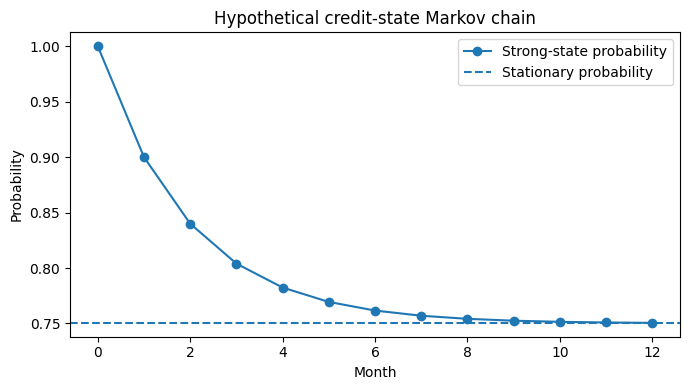

In [13]:
# Import plotting tools for the probability trajectory.
import matplotlib.pyplot as plt

# Collect the Strong-state probability from each simulated month.
strong_probabilities = np.array(history)[:, 0]

# Create a plot of the probability trajectory.
plt.figure(figsize=(7, 4))

# Plot the probability of the Strong state at each month.
plt.plot(range(len(strong_probabilities)), strong_probabilities, marker='o', label='Strong-state probability')

# Add the stationary probability as a reference line.
plt.axhline(stationary[0], linestyle='--', label='Stationary probability')

# Label axes and add a legend.
plt.xlabel('Month')
plt.ylabel('Probability')
plt.title('Hypothetical credit-state Markov chain')
plt.legend()
plt.tight_layout()
plt.show()

## 16. Exercises — solutions (check after attempting)

1. **Rebalance:** $q'=(600,12,5)^\top$ and $V'=\$5{,}000$.
2. **PnL:** $10(-10)+5(20)=\$0$.
3. **Arbitrage:** No. A zero-cost portfolio may have negative payoffs in some states.
4. **Replication:** Yes: hold $(2,1)$ in the two basis assets.
5. **Dimensions:** $Aq\in\mathbb R^3$, one payoff for each scenario.
6. **Markov transition:** $\pi_1=(0.9,0.1)^\top$.
7. **Constant payoff:** $q=(1,1)^\top$.
8. **Discounting:** $100(0.95)=\$95$.
9. **Underdetermined system:** There may be a nonzero vector in $\ker A$; adding it to one solution gives another with the same payoff. Existence is still required.
10. **Stationarity:** $A\pi_*=\pi_*$ is precisely the eigenvector equation for eigenvalue 1.
11. **Centering:** Without centering, SVD can capture the mean level instead of variation about the mean; conventional PCA of covariance uses centered observations.
12. **Identity transition:** $I\pi=\pi$ for every probability vector, so the initial distribution never changes and no unique common limiting distribution exists.

## 17. Suggested extensions (beyond the lecture)

- **Real portfolio data:** Download daily adjusted stock prices from a reliable provider, form holdings and price vectors, and calculate PnL. Distinguish price changes from dividends and stock splits.
- **Risk and covariance:** Estimate a return covariance matrix $\Sigma$ and compute portfolio variance $w^\top\Sigma w$ for investment weights $w$.
- **Scenario hedging:** Construct a payoff matrix for a stock and simple derivative, then solve for replicating portfolios and compare their prices.
- **PCA of returns:** Use SVD to compare common factors across a larger set of stocks, and test the stability of components across different time windows.

These are extensions suggested for practice, not claims that they are covered in the supplied slides.

### References

1. Peter J. Kempthorne, **MIT 18.642, Lecture 2: Linear Algebra**, Fall 2024, supplied lecture PDF, slides 1–35. MIT OpenCourseWare: https://ocw.mit.edu/
2. Gilbert Strang, *Introduction to Linear Algebra* — background on matrix algebra, eigenvectors, and SVD.
3. Steven E. Shreve, *Stochastic Calculus for Finance I: The Binomial Asset Pricing Model* — further study of finite-state no-arbitrage and pricing.
4. Sheldon Ross, *Introduction to Probability Models* — background on Markov chains.

**Convention reminder:** All stock prices, scenario probabilities, and returns in this notebook are synthetic teaching examples.